Linear Regression
objective: build model which learn from dataset and predict salary for a given number of years of experience
dataset: salary.csv

Scikit-learn is an open-source Python library that simplifies the process of building machine learning models.

In [1]:
pip install scikit-learn

   ---------------------------------------- 0.0/8.0 MB ? eta -:--:--
   - -------------------------------------- 0.3/8.0 MB ? eta -:--:--
   --- ------------------------------------ 0.8/8.0 MB 1.9 MB/s eta 0:00:04
   ------ --------------------------------- 1.3/8.0 MB 2.3 MB/s eta 0:00:03
   ---------- ----------------------------- 2.1/8.0 MB 2.7 MB/s eta 0:00:03
   ----------------- ---------------------- 3.4/8.0 MB 3.3 MB/s eta 0:00:02
   ---------------------- ----------------- 4.5/8.0 MB 3.7 MB/s eta 0:00:01
   ---------------------------- ----------- 5.8/8.0 MB 4.0 MB/s eta 0:00:01
   ----------------------------------- ---- 7.1/8.0 MB 4.3 MB/s eta 0:00:01
   ---------------------------------------- 8.0/8.0 MB 4.3 MB/s  0:00:01

   ------------- -------------------------- 1/3 [joblib]
   ------------- -------------------------- 1/3 [joblib]
   ------------- -------------------------- 1/3 [joblib]
   ------------- -------------------------- 1/3 [joblib]
   ------------- -----------


[notice] A new release of pip is available: 26.0.1 -> 26.1.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [ ]:
import warnings
warnings.filterwarnings("ignore")

In [ ]:
import matplotlib.pyplot as plot
import pandas as pd
import numpy as np
import pylab as pl
%matplotlib inline 
#%matplotlib inline :it is used for display the plots below each cell

pd.options.display.float_format='{:,.2f}'.format
float_formatter=lambda x: "%4.f" %x
np.set_printoptions(formatter={'float_kind':float_formatter})

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression #Algorithm used for prediction.

data=pd.read_csv('Salary_Data.csv')
print('Dataset size:', data.shape)
data.head()


Dataset size: (30, 2)


,YearsExperience,Salary
0,1.10,"39,343.00"
1,1.30,"46,205.00"
2,1.50,"37,731.00"
3,2.00,"43,525.00"
4,2.20,"39,891.00"


In [ ]:
#define feature and target data
x=data.iloc[:,:-1].values #Take all rows and all columns except last. Experience becomes Feature (X)
y=data.iloc[:,1].values #Take all rows from last column.Salary becomes Target (Y).
#split data to 10-test, 2-train
xTrain, xTest, yTrain, yTest,=train_test_split(x,y,test_size=1/3,random_state=0)
# Meaning:
# 67% Training Data
# 33% Testing Data
#example:30 records training:20rows,testing=10rows




In [ ]:
#linear regression
lr=LinearRegression()#object
lr.fit(xTrain,yTrain)#here model is trained. model lerans relationship:salary and experience
yPred=lr.predict(xTest)#Predicts salaries for testing data.

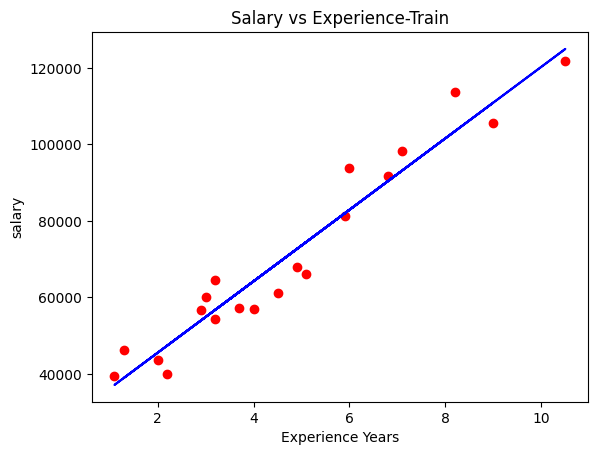

In [ ]:
#plot chart
plot.scatter(xTrain,yTrain,color='red')#Shows actual datapoints
plot.plot(xTrain,lr.predict(xTrain),color='blue')#Shows best fit line.
plot.title('Salary vs Experience-Train')
plot.xlabel("Experience Years")
plot.ylabel("salary")
plot.show()

In [ ]:
#print model score , coef and intercept
print("Model score :",round(lr.score(xTrain,yTrain),4))#Returns R² Score. meaning: % accuracy of fitting data
print('Coef         :',lr.coef_)#slope meaning: Every additional year of experience increases salary by about
print('Intercept    :',round(lr.intercept_,4))#Linear Regression Equation:Salary =26780 + 9345 × Experience

Model score : 0.9382
Coef         : [9346]
Intercept    : 26816.1922


In [8]:
new_sexp=float(input("Enter experience in years:"))
predict_salary=lr.predict([[new_sexp]])
print(predict_salary)

[73546]


- pickle is a built-in Python module used to serialize and deserialize objects, allowing you to save trained models to disk and reload them later without retraining.
- Joblib is a Python library used in machine learning for efficient model saving/loading (serialization) and parallel processing. 


In [ ]:
import pickle #pickle is a library used for saving machine learning model

In [ ]:
with open('model_pickel',"wb") as f:
    pickle.dump(lr,f) #Stores trained model into a file. file created so that So you don't need to train again.

In [ ]:
with open('model_pickel',"rb") as f:
    model=pickle.load(f)#reads saved file
    predicted_salary=model.predict([[5]])
    print(predicted_salary)

[73546]


In [ ]:
import joblib #it is a python library used for save and load the model
joblib.dump(lr,'model_joblib')

['model_joblib']

In [13]:
jobmodel=joblib.load('model_joblib')


In [ ]:
jobmodel.predict([[7]])#Predicts salary for 7 years experience.

array([92238])